/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


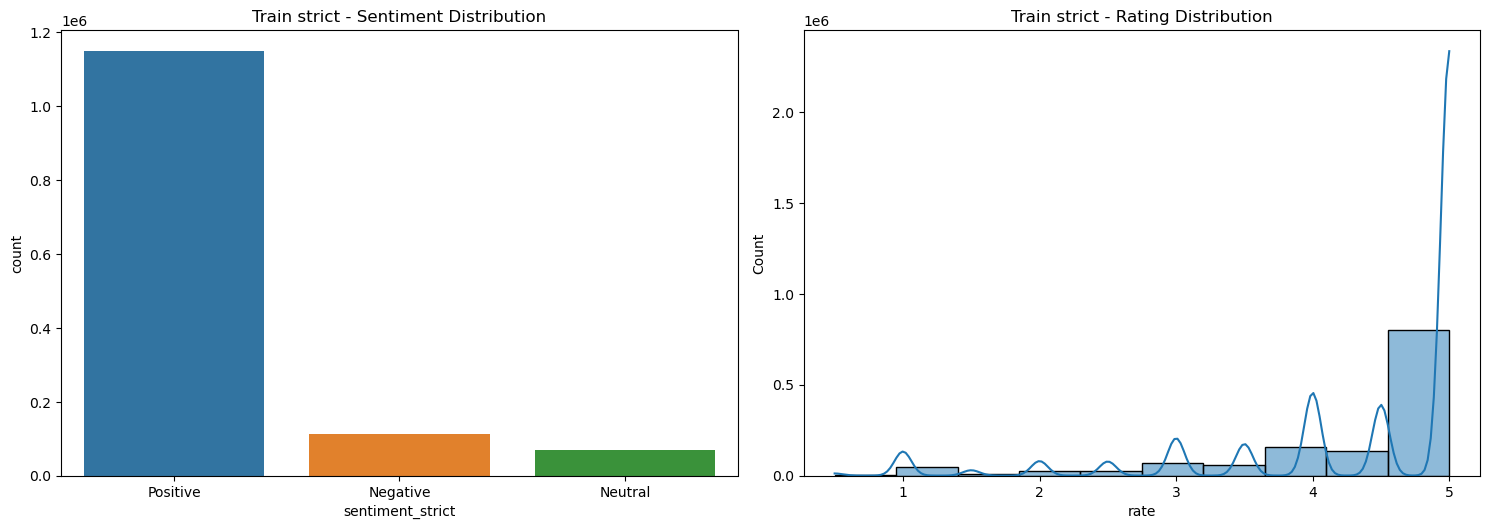

/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


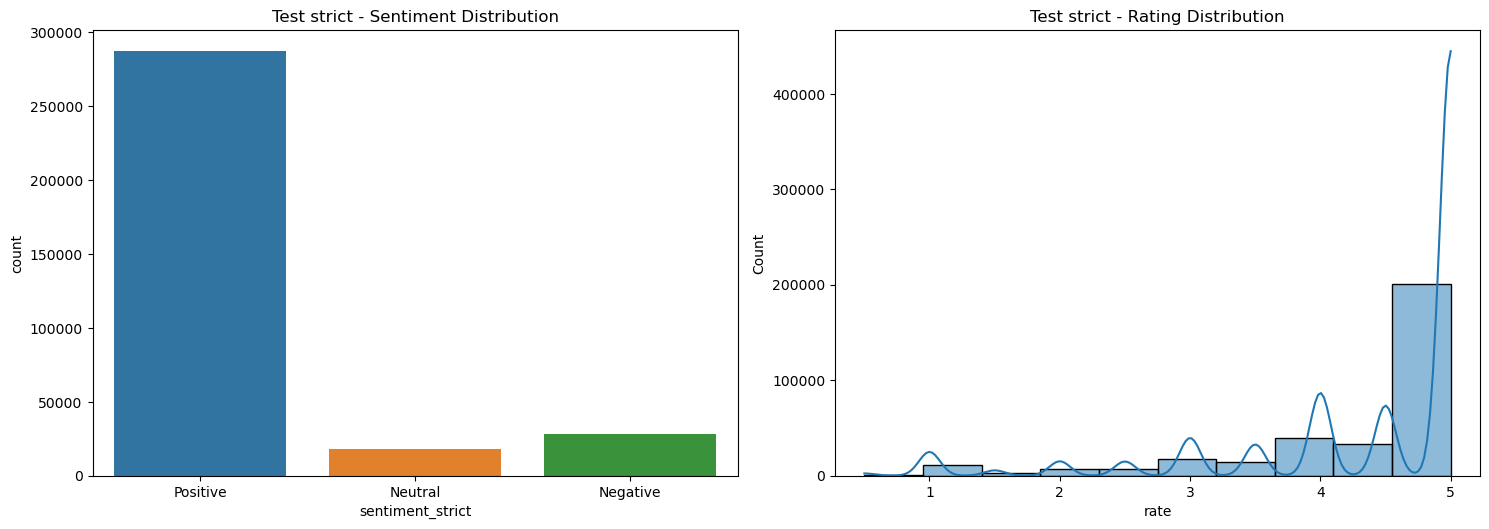

/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


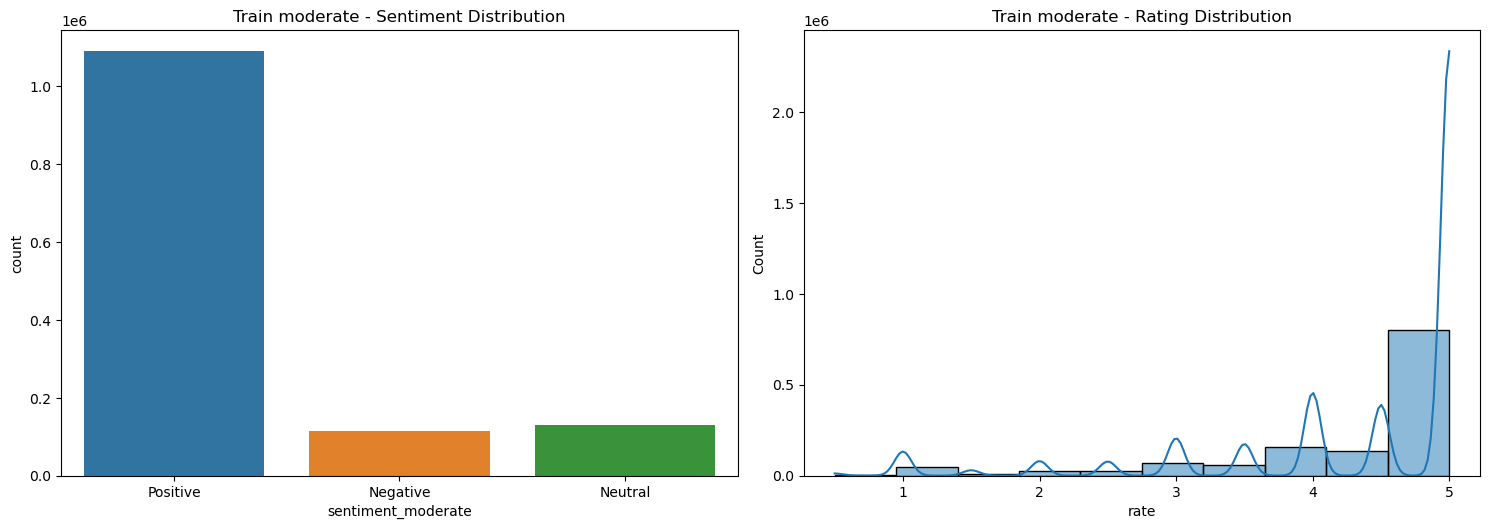

/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


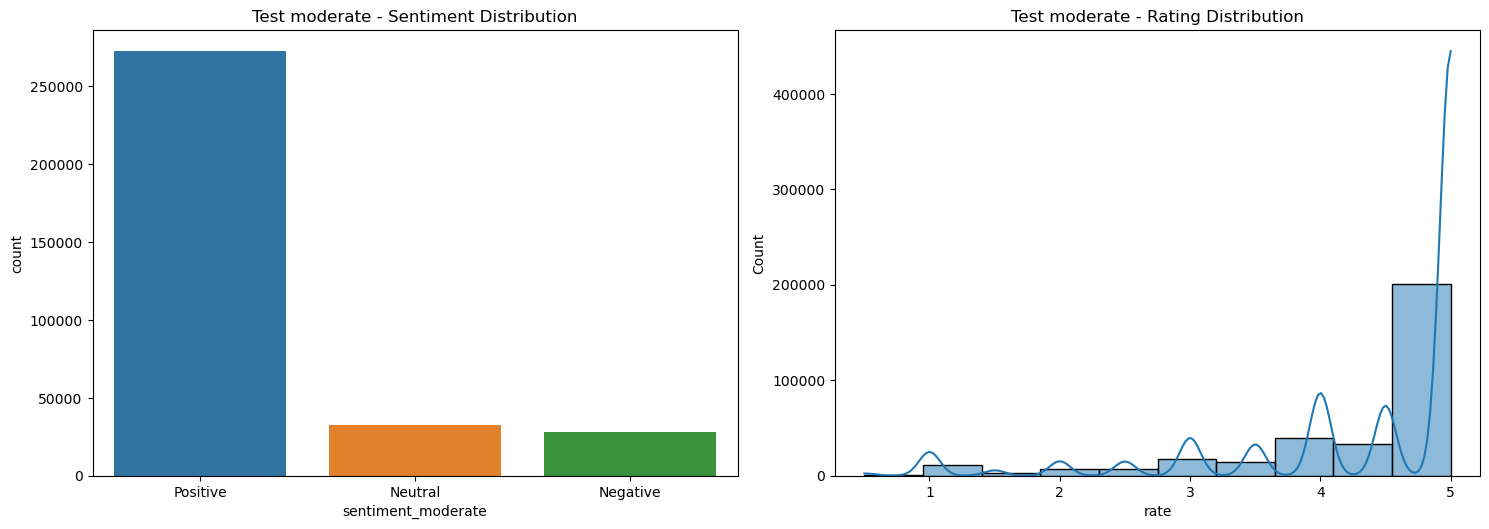

/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


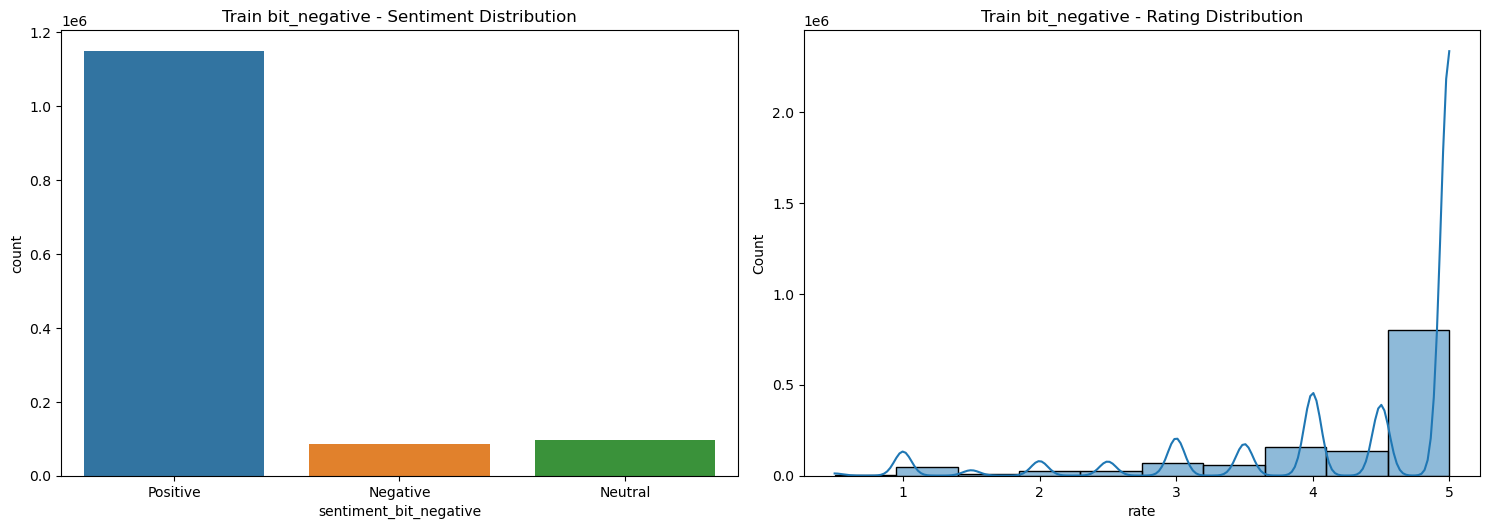

/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


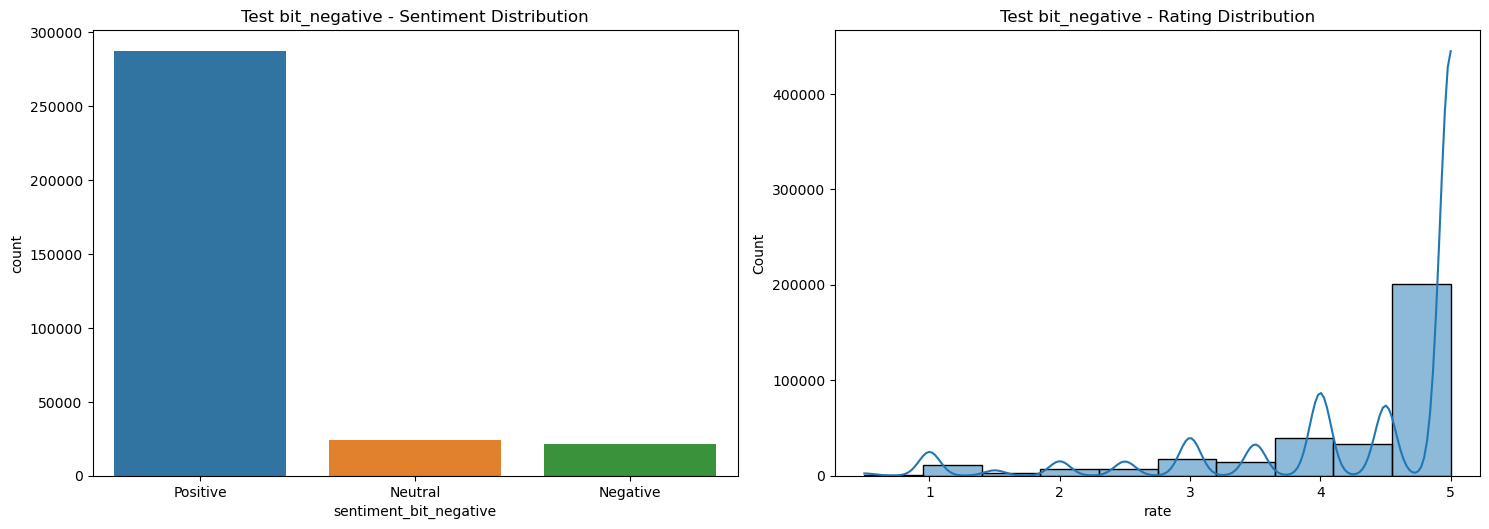

/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


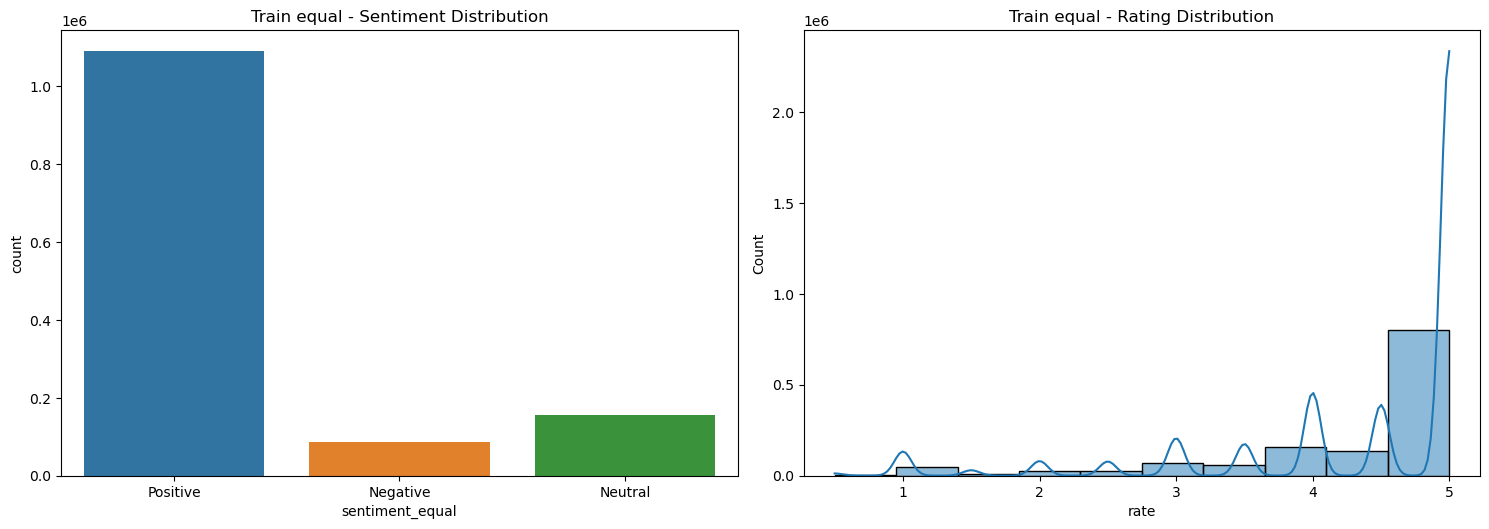

/Users/sarutsunpawatr/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


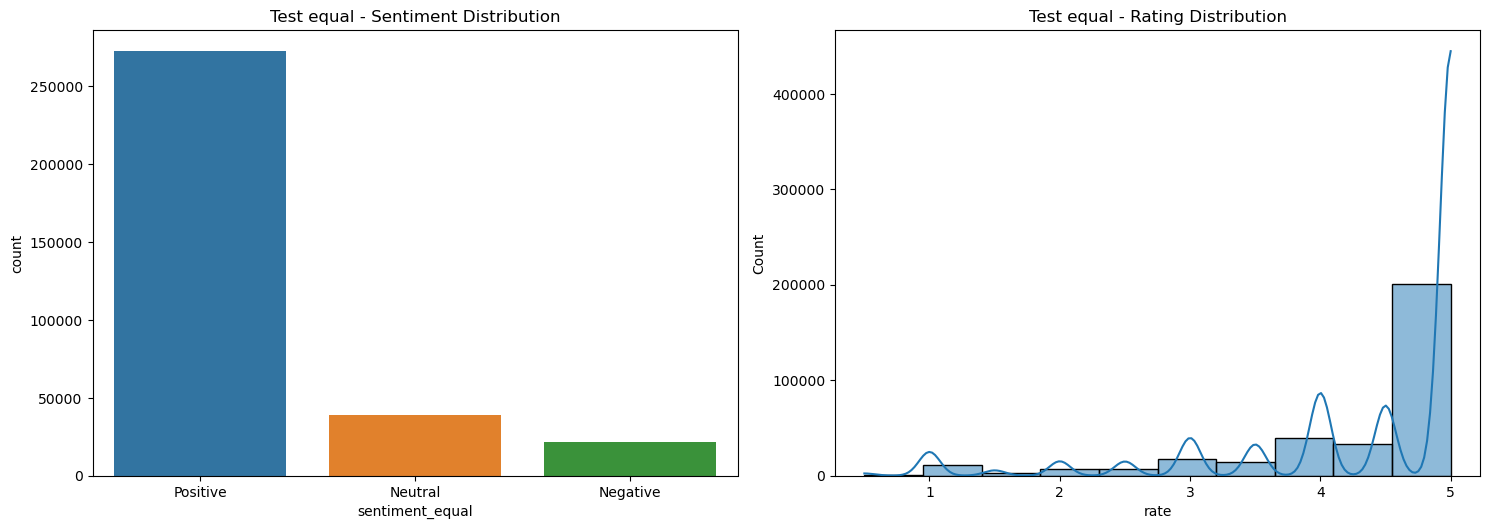

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv('Udemy_grouped_by_category.csv')

# Turnning ratings into sentiment classes.
def set_sentiment(rating, neutral_condition):
    if neutral_condition(rating):
        return 'Neutral'
    elif rating < 3:
        return 'Negative'
    else:
        return 'Positive'

def perform_eda(data, title, sentiment_col):
    plt.figure(figsize=(15, 10))
    
    plt.subplot(2, 2, 1)
    sns.countplot(x=sentiment_col, data=data)
    plt.title(f'{title} - Sentiment Distribution')
    
    plt.subplot(2, 2, 2)
    sns.histplot(data['rate'], bins=10, kde=True)
    plt.title(f'{title} - Rating Distribution')
    
    plt.tight_layout()
    plt.show()
    plt.savefig(f'{title}_eda.png')
    plt.close()

# Neutral condition
neutral_conditions = [
    ('strict', lambda x: x == 3),
    ('moderate', lambda x: 3 <= x <= 3.5),
    ('bit_negative', lambda x: 2.5 <= x <= 3),
    ('equal', lambda x: 2.5 <= x <= 3.5)
]

for condition_name, condition_func in neutral_conditions:
    df[f'sentiment_{condition_name}'] = df['rate'].apply(lambda x: set_sentiment(x, condition_func))
    
# Seperate train and test sets for further processes.
    train, test = train_test_split(df, test_size=0.2, random_state=42)
    
    train.to_csv(f'train_{condition_name}.csv', index=False)
    test.to_csv(f'test_{condition_name}.csv', index=False)
    
    perform_eda(train, f'Train {condition_name}', f'sentiment_{condition_name}')
    perform_eda(test, f'Test {condition_name}', f'sentiment_{condition_name}')

